<h3 align="center"> <b>Autores:</b> <i>Arturo Sarrión Sánchez y Juan Carlos Fernandez Abril</i></h3>

**Práctica 1**

Notebook centrado en cómo implementar y probar heurísticas nuevas, así como en la comparación de heurísticas. 

Es el cuaderno principal para desarrollar y validar las nuevas funciones heurísticas solicitadas en la práctica.

In [6]:
pip install matplotlib tabulate numpy

Note: you may need to restart the kernel to use updated packages.


In [7]:
# Dependencias de código
import search
from search import *

In [8]:
# Estado de referencia 3x3
size = 3
initial_state_matrix = [[7, 8, 1], [4, 0, 6], [2, 3, 5]]
end_state_matrix = [[1, 2, 3], [8, 0, 4], [7, 6, 5]]
initial_state = [n for row in initial_state_matrix for n in row]
end_state     = [n for row in end_state_matrix for n in row]

**Método que implementa una nueva heurística**

En este caso la nueva heurística es simplemente multiplicar por 2 la distancia de Manhatann

In [9]:
# Nueva heurística a probar: 2 * distancia de Manhattan
def nueva_heuristica(state, end_state):
    """
    Heurística que multiplica por 2 la distancia Manhattan 
    """
    return 2 * getManhattanDistance(state, end_state) 

# Una sola línea basta para que run_algorithm y run_all_algorithms la conozcan.
# Se registra con include_in_all=False para no añadirla a la tabla de la actividad 6.
register_heuristic("Nueva Heurística", nueva_heuristica, include_in_all=False)

# **Piezas descolocadas** *(Pregunta 1)*

In [10]:
def get_piezas_descolocadas(state, end_state): 
    """
    Compara todas las piezas y suma 1 por cada pieza descolocada
    """

    total = 0 # 

    descolocadas = 0 # Variable global para saber el nº de fichas descolocadas
    for i in range (1, len(state)):
        
        posAct = state.index(i)
        posEnd = end_state.index(i)
        
        colocada = abs(posAct - posEnd)

        if (colocada != 0): # por las propiedaddes del puzzle (mat. y col.)
            descolocadas += 1
        
    return descolocadas 

register_heuristic("A (Piezas descolocadas)", get_piezas_descolocadas)

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

print("A (Piezas descolocadas):", get_piezas_descolocadas(initial_state, end_state))

A (Piezas descolocadas): 7


# **Distancia Euclíeda** *(Pregunta 2)*

Esta es una búsqueda de tipo A que utiliza la
distancia Euclídea como función heurística; la expansión de los nodos se realiza siguiendo la
función f(n)=g(n)+D(n), donde g(n) es el factor coste correspondiente a la profundidad del nodo n
en el árbol de búsqueda y h(n)=D(n) es la distancia Euclídea, es decir, la suma de las distancias en
línea recta de cada ficha del puzzle desde su posición actual a la posición que ocupará en el
objetivo (raíz cuadrada de la suma de los cuadrados de las distancias horizontal y vertical).


In [11]:
def get_euclidean(state, end_state):

    total = 0

    size = math.sqrt(len(state))

    for i in range (1, len(state)):

        # Pos 2D en estado actual
        posAct = state.index(i)

        filaAct = posAct // size
        colAct = posAct % size

        # Pos 2D en estado final
        posFin = end_state.index(i)

        filaFin = posFin // size
        colFin = posFin % size

        # Distancia Euclídea de la ficha i
        dist = math.sqrt((filaAct - filaFin)**2 + (colAct - colFin)**2)

        # Acumulo el valor
        total += dist

    # Devolvemos la parte entera para evitar el falso contraejemplo de consistencia
    # por coma flotante; la diferencia real entre dos estados vale 1.
    return math.floor(total)

register_heuristic("A (Euclídea)", get_euclidean)

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

print("A (Euclídea):", get_euclidean(initial_state, end_state))

A (Euclídea): 13


# **Filas-Columnas** *(Pregunta 3)* 

Esta heurística funciona del siguiente modo: para cada ficha del tablero, si la ficha no está en
su fila destino correcta se suma 1 punto; si la ficha no está en su columna destino correcta se
suma 1 punto. Por tanto, el mínimo valor de esta heurística para una ficha es 0 (cuando la ficha
está colocada correctamente en su posición objetivo), y el máximo valor es 2 (cuando ni la fila ni
la columna de la posición de la ficha son iguales a valor de la fila y columna de la posición
objetivo).

In [12]:
def get_filas_columnas(state, end_state):
    
    points = 0
    
    size = math.sqrt(len(state))

    for i in range (1, len(state)):

        posAct = state.index(i)
        
        filaAct = posAct // size
        colAct = posAct % size

        posFin = end_state.index(i)
        
        filaFin = posFin // size
        colFin = posFin % size

        # +1 si la ficha no está en su fila destino; +1 si no está en su columna destino
        if filaAct != filaFin:
            points += 1
        if colAct != colFin:
            points += 1

    return points
        
register_heuristic("A (filas_columnas)", get_filas_columnas)

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

print("A (filas_columnas):", get_filas_columnas(initial_state, end_state))

A (filas_columnas): 11


# **Euclíeda + LC** *(Pregunta 4)*

Esta estrategia implementa una búsqueda de tipo A que utiliza una heurística
informada basada en la combinación de la distancia Euclídea y los conflictos lineales (LC).
La expansión de nodos se realiza con la función f(n)=g(n)+h(n), donde g(n) es el coste asociado al
nivel de profundidad del nodo n y h(n)=D(n)+LC(n), siendo D(n) la distancia Euclídea y LC(n)
el número de conflictos entre fichas mal colocadas en la misma fila o columna que deben
cruzarse. Esta heurística mejora la precisión respecto a A* Manhattan, ya que añade
penalizaciones por conflictos que implican movimientos adicionales necesarios.

In [13]:
def get_euclidean_and_LC(state, end_state):
    
    return get_euclidean(state, end_state) + getLinear_conflict(state, end_state)

register_heuristic("A (Euclídea + LC)", get_euclidean_and_LC)

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

print("A (Euclídea + LC):", get_euclidean_and_LC(initial_state, end_state))

A (Euclídea + LC): 13


# **Propuesta: heurística inventada** *(Pregunta 5)*

Combinamos tres de las heurísticas anteriores en una sola:

    h(n) = max( D_Manhattan(n), FilCol(n) + LC(n) )

donde D_Manhattan es la distancia de Manhattan, FilCol el número de fallos de fila/columna y LC la
penalización por conflictos lineales. Como FilCol(n) ≤ D_Manhattan(n), la heurística queda acotada
entre D_Manhattan y D_Manhattan + LC, de modo que **es admisible** (nunca supera el coste real) y,
además, **domina a Manhattan**, por lo que A* debería expandir menos nodos. El estudio de la
actividad 6 no encuentra contraejemplos de consistencia en los 181 440 estados alcanzables, por lo
que también la declaramos **consistente**.

In [14]:
def get_manhattan_filcol_lc(state, end_state):
    """Heurística inventada (actividad 5): max(D_Manhattan, FilCol + LC). Admisible y consistente."""
    return max(getManhattanDistance(state, end_state),
               get_filas_columnas(state, end_state) + getLinear_conflict(state, end_state))

register_heuristic("A (Propuesta)", get_manhattan_filcol_lc)

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

print("A (Propuesta) max(MD, FilCol + LC):", get_manhattan_filcol_lc(initial_state, end_state))

A (Propuesta) max(MD, FilCol + LC): 16


**Ejemplo con tamaño 3**

Se define el estado inicial y el final, se ejecutan todos los algoritmos disponibles y se visualizan los resultados

BFS executed
DFS-B executed
ID executed
Voraz (Manhattan) executed
A* (Manhattan) executed
A (MD + LC) executed
IDA* (Manhattan) executed
A (Piezas descolocadas) executed
A (Euclídea) executed
A (filas_columnas) executed
A (Euclídea + LC) executed
A (Propuesta) executed
+-------------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| Algorithm               |   Cost |   Depth |    Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+=========================+========+=========+=============+===================+==================+====================+
| BFS                     |     22 |      23 | 1.2197      |            233687 |            86871 |             110729 |
+-------------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| DFS-B                   |     38 |      40 | 5.76918     |           2028383 |          1301341 |                 76 |
+--

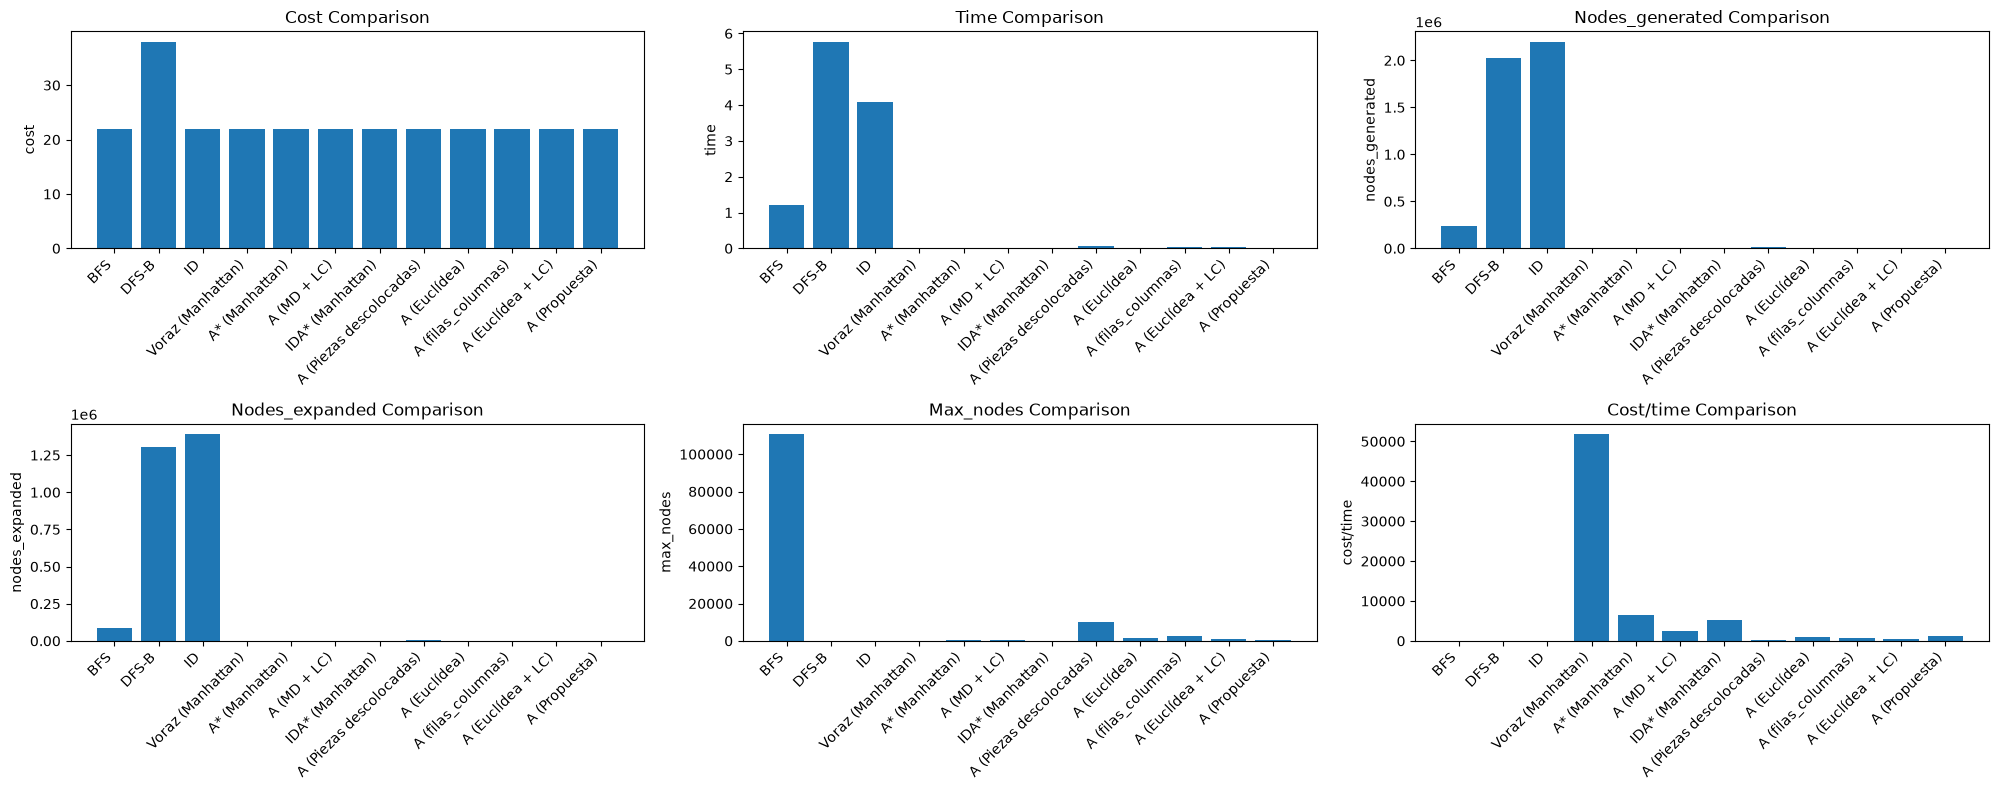

In [ ]:
# Tamaño 3

size = 3  # Example for a 3x3 puzzle

initial_state_matrix = [
    [7, 8, 1],
    [4, 0, 6],
    [2, 3, 5]
]


end_state_matrix = [
    [1, 2, 3],
    [8, 0, 4],
    [7, 6, 5]
]

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

# Ejecutar todos los algoritmos y mostrar los resultados en una tabla
results = {}
if isSolvable(initial_state, end_state):
    # Llamar a la función para ejecutar todos los algoritmos
    results = run_all_algorithms(initial_state, end_state, size, 40)
    show_results(results)
    plot_algorithm_comparison(results)
else:
    print("The puzzle is not solvable.")

# **Estudio de admisibilidad y consistencia** *(Pregunta 6)*

Para el estado inicial anterior se compara el valor de la heurística con el coste óptimo obtenido mediante BFS. Después se utiliza `check_consistency` para buscar un posible contraejemplo de consistencia. Estas comprobaciones sobre un único ejemplo aportan evidencia, pero no constituyen una demostración general.

In [16]:
# Estudio de admisibilidad para el estado inicial anterior
h_initial = nueva_heuristica(initial_state, end_state)
h_goal = nueva_heuristica(end_state, end_state)
optimal_cost = results['BFS']['cost']

print("Valor en el estado inicial:", h_initial)
print("Valor en el estado objetivo:", h_goal)
print("Coste óptimo obtenido con BFS:", optimal_cost)
print("¿Es no negativa en este ejemplo?", h_initial >= 0)
print("¿Vale cero en el objetivo?", h_goal == 0)
print("¿No supera el coste óptimo?", h_initial <= optimal_cost)

# Estudio de consistencia desde el mismo estado inicial
consistency_result = check_consistency(
    nueva_heuristica, initial_state, end_state, size, max_states=10000
)
print("Resultado de la prueba de consistencia:")
print(consistency_result)


Valor en el estado inicial: 32
Valor en el estado objetivo: 0
Coste óptimo obtenido con BFS: 22
¿Es no negativa en este ejemplo? True
¿Vale cero en el objetivo? True
¿No supera el coste óptimo? False
Resultado de la prueba de consistencia:
{'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [7, 8, 1, 4, 0, 6, 2, 3, 5], 'child': [7, 0, 1, 4, 8, 6, 2, 3, 5], 'h_state': 32, 'h_child': 30, 'step_cost': 1}}


In [17]:
# Declaración de admisibilidad y consistencia de cada heurística nueva (actividad 6).
# El coste óptimo de referencia se ha obtenido con BFS en la celda anterior.
heur_estudio = {
    'A (Piezas descolocadas)': get_piezas_descolocadas,
    'A (Euclídea)':            get_euclidean,
    'A (filas_columnas)':      get_filas_columnas,
    'A (Euclídea + LC)':       get_euclidean_and_LC,
    'A (Propuesta)':           get_manhattan_filcol_lc,
}

optimo = results['BFS']['cost']
print("Coste óptimo de referencia (BFS) =", optimo)

for nombre, h in heur_estudio.items():
    h_ini = h(initial_state, end_state)
    h_obj = h(end_state, end_state)
    # max_states=None explora todos los estados alcanzables (181 440 en el 3x3)
    cons = check_consistency(h, initial_state, end_state, size, max_states=None)
    print(f"\n--- {nombre} ---")
    print(f"  h(inicial)  = {h_ini}")
    print(f"  h(objetivo) = {h_obj}")
    print(f"  ¿No supera el coste óptimo ({optimo})? {h_ini <= optimo}")
    print(f"  consistencia: {cons}")

Coste óptimo de referencia (BFS) = 22

--- A (Piezas descolocadas) ---
  h(inicial)  = 7
  h(objetivo) = 0
  ¿No supera el coste óptimo (22)? True
  consistencia: {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}

--- A (Euclídea) ---
  h(inicial)  = 13
  h(objetivo) = 0
  ¿No supera el coste óptimo (22)? True
  consistencia: {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}

--- A (filas_columnas) ---
  h(inicial)  = 11
  h(objetivo) = 0
  ¿No supera el coste óptimo (22)? True
  consistencia: {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}

--- A (Euclídea + LC) ---
  h(inicial)  = 13
  h(objetivo) = 0
  ¿No supera el coste óptimo (22)? True
  consistencia: {'consistent': False, 'complete': False, 'states_checked': 7, 'counterexample': {'state': [0, 7, 1, 4, 8, 6, 2, 3, 5], 'child': [4, 7, 1, 0, 8, 6, 2, 3, 5], 'h_state': 15, 'h_child': 13, 'step_cost': 1}}

--- A (Pr

# **Declaración de admisibilidad y consistencia** *(actividad 6)*

| Heurística | h(inicial) | h(objetivo) | ¿Admisible? | Consistencia (`check_consistency`) |
|---|---|---|---|---|
| A (Piezas descolocadas) | 7 | 0 | Sí | Consistente: 181 440 estados, sin contraejemplo |
| A (Euclídea) | 13 | 0 | Sí | Consistente: 181 440 estados, sin contraejemplo |
| A (filas_columnas) | 11 | 0 | Sí | Consistente: 181 440 estados, sin contraejemplo |
| A (Euclídea + LC) | 13 | 0 | Sí | **No consistente**: contraejemplo con 7 estados |
| A (Propuesta) | 16 | 0 | Sí | Consistente: 181 440 estados, sin contraejemplo |

- **A (Piezas descolocadas):** h(objetivo)=0, nunca es negativa y h(inicial)=7 ≤ 22 ⇒ **admisible**;
  un movimiento solo recoloca una ficha, así que W(n) ≤ 1 + W(n') ⇒ **consistente**.
- **A (Euclídea):** h(objetivo)=0 y h(inicial)=13 ≤ 22 ⇒ **admisible**; los 181 440 estados
  alcanzables se exploran sin contraejemplo ⇒ **consistente**. Se devuelve truncada ⌊D(n)⌋ para
  evitar el falso contraejemplo por coma flotante de la versión exacta (diferencia 1.0000000000000018).
- **A (filas_columnas):** h(objetivo)=0 y h(inicial)=11 ≤ 22 ⇒ **admisible**; un movimiento solo
  altera la fila o la columna de una ficha, así que cambia como mucho en 1 ⇒ **consistente**.
- **A (Euclídea + LC):** en el ejemplo es admisible (13 ≤ 22), pero **no es consistente**: el código
  encuentra el contraejemplo h(n)=15 frente a h(n')=13 con n=[0,7,1,4,8,6,2,3,5], es decir,
  15 > 1 + 13.
- **A (Propuesta):** h(objetivo)=0 y h(inicial)=16 ≤ 22 ⇒ **admisible**; los 181 440 estados
  alcanzables se exploran sin contraejemplo ⇒ **consistente**.

> La exploración completa de los 181 440 estados alcanzables aporta evidencia experimental, pero no
> constituye una demostración general (tal y como indica el boletín).

## Resultados heurísticas *(tabla boletín)* 

| Métrica | BFS | DFS(Back) | Voraz | ID | Manh | MD+LC | Euclid | IDA*Manh | Desc | FilCol | Euclid+LC | Propuesta |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| *Nodes generated* | 233 687 | 2 028 383 | 82 | 2 198 820 | 704 | **415** | 2 829 | 1 409 | 17 460 | 4 363 | 1 779 | 679 |
| *Nodes expanded* | 86 871 | 1 301 341 | 30 | 1 390 965 | 266 | **158** | 1 057 | 882 | 6 452 | 1 601 | 666 | 256 |
| *Max nodes stored* | 110 729 | **76** | 54 | 43 | 429 | 251 | 1 681 | 35 | 10 068 | 2 603 | 1 060 | 414 |
| *Solution cost* | 22 | 38 | 22 | 22 | 22 | 22 | 22 | 22 | 22 | 22 | 22 | 22 |
| *Search depth* | 23 | 40 | 22 | 22 | 22 | 22 | 22 | 22 | 22 | 22 | 22 | 22 |
| *Running time (s)* | 0,628 | 2,899 | 0,0004 | 3,144 | **0,0033** | 0,0082 | 0,0222 | 0,0041 | 0,0683 | 0,0267 | 0,0401 | 0,0170 |

Todas las heurísticas **admisibles y consistentes** obtienen el **coste óptimo 22**. Entre las
búsquedas A\*, `A (MD + LC)` es la que **menos expande (158 nodos)** y la que **menos memoria usa
(251 nodos)**, mientras que `A* (Manhattan)` es la **más rápida (0,0033 s)**.

**Pregunta**

¿Cómo se comporta la nueva heurística?  ¿Es A*?  ¿Puedes estar seguro/a?

**Respuesta:**

La heurística 2·Manhattan vale **32** en el estado inicial, mientras que el coste **óptimo** de ese
mismo puzzle (obtenido con BFS) es **22**. Como 32 > 22, la heurística **sobreestima** el coste
restante y, por tanto, **no es admisible** (`¿No supera el coste óptimo?` → `False`). La prueba de
consistencia lo confirma: encuentra un contraejemplo en el primer estado (h(n)=32, h(n')=30 y
32 > 1 + 30), así que tampoco es **consistente**.

Aunque la hayamos ejecutado dentro de un algoritmo A*, al **no ser admisible no podemos estar
seguros** de que la solución sea óptima: A* solo garantiza el óptimo con heurísticas admisibles (y,
en la práctica, consistentes). En conclusión, el algoritmo *encuentra* solución, pero **no podemos
garantizar** que sea la de coste mínimo.

**Prueba con tamaño 4**

In [18]:
 # Tamaño 4

size = 4
initial_state_matrix = [
    [13, 2, 10, 3],
    [1, 12, 8, 4],
    [5, 0, 9, 6],
    [15, 14, 11, 7]
]


end_state_matrix = [
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 0]
]

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

# Ejecutar algoritmos concretos incluyendo nueva heurística
results = {}
if isSolvable(initial_state, end_state):
    # Llamar a la función para ejecutar los algoritmos
    algo_result = run_algorithm('A* (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)
    
    algo_result = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)

    algo_result = run_algorithm('Nueva Heurística', initial_state, end_state, size)
    results.update(algo_result)
        
    show_results(results)
else:
    print("The puzzle is not solvable.")


A* (Manhattan) executed
Voraz (Manhattan) executed
Nueva Heurística executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| A* (Manhattan)    |     41 |      41 | 10.463     |            645273 |           215568 |             403054 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Voraz (Manhattan) |    111 |     127 |  0.0399182 |              4983 |             1594 |               3277 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Nueva Heurística  |     47 |      48 |  1.11262   |            121708 |            35397 |              72042 |
+----------

**Pregunta** 

¿Y qué opinas ahora ?

**Respuesta:**

En el puzzle 4×4 ocurre exactamente lo mismo. La salida anterior muestra:

- `A* (Manhattan)` → coste **41** (el óptimo),
- `Nueva Heurística` → coste **47**,
- `Voraz (Manhattan)` → coste **111**.

De nuevo 47 > 41: la heurística **vuelve a sobreestimar** el coste y A* devuelve una solución
**subóptima**, así que reiteramos que **no es admisible ni consistente**. El efecto se acentúa al
crecer el tablero, porque multiplicar por 2 la distancia de Manhattan acumula la sobreestimación en
más fichas.

**Ejemplo con tamaño 5**

In [19]:
# Tamaño 5

size = 5
initial_state_matrix = [
  [1, 2, 3, 4, 5],
  [6, 7, 8, 9, 10],
  [0, 12, 13, 14, 15],
  [16, 17, 18, 19, 20],
  [21, 22, 24, 23, 11]
]

end_state_matrix = [
  [1, 2, 3, 4, 5],
  [6, 7, 8, 9, 10],
  [11, 12, 13, 14, 15],
  [16, 17, 18, 19, 20],
  [21, 22, 23, 24, 0]
]

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

# Ejecutar un par de algoritmos concretos
results = {}
if isSolvable(initial_state, end_state):
    # Llamar a la función para ejecutar los algoritmos
    algo_result = run_algorithm('A* (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)
    
    algo_result = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)

    algo_result = run_algorithm('Nueva Heurística', initial_state, end_state, size)
    results.update(algo_result)
        
    show_results(results)

else:
    print("The puzzle is not solvable.")



A* (Manhattan) executed
Voraz (Manhattan) executed
Nueva Heurística executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| A* (Manhattan)    |     30 |      30 |   4.94019  |            182180 |            55355 |             121598 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Voraz (Manhattan) |    138 |     138 |   0.146407 |              5718 |             1688 |               3985 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Nueva Heurística  |     30 |      30 |   0.34443  |             13130 |             3871 |               8823 |
+----------

**Prueba con tamaño n generando automaticamente estados finales e iniciales**

Se plantea como generalizar a n el tamaño del puzzle

In [ ]:
# Prueba con tamaño n generando automaticamente estados finales e iniciales 
size = 3
end_state = generate_ordered_state(size)
#end_state = generate_spiral_state(size)
initial_state = generate_random_state(size, end_state)


print("Initial state:\n")
visualize_state(initial_state)

print("\nEnd state:\n")
visualize_state(end_state)

# Ejecutar unos algoritmos concretos
results = {}

alg_results = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)
results.update(alg_results)
alg_results = run_algorithm('A* (Manhattan)', initial_state, end_state, size)
results.update(alg_results)
alg_results = run_algorithm('A (MD + LC)', initial_state, end_state, size)
results.update(alg_results)
algo_result = run_algorithm('Nueva Heurística', initial_state, end_state, size)
results.update(algo_result)

show_results(results)
plot_algorithm_comparison(results)

#show_path_for_algorithm(results, 'A (MD + LC)', size)